## 1. Setup & Imports

In deze stap importeer ik alle nodige PySpark functies en modules die ik zal gebruiken in de rest van het notebook.

Ik gebruik voornamelijk:
- PySpark SQL functions voor transformaties
- Window functions voor SCD en deduplicatie
- Date/time functies voor de datumdimensie
- Hash functies voor SCD Type 2

Deze imports vormen de basis voor het bouwen van de medallion architectuur.

In [ ]:
!pip install pyspark -q

from pyspark.sql import SparkSession, functions as F
import os, glob, shutil
import matplotlib.pyplot as plt

spark = (SparkSession.builder
    .appName("AdvWorks_Medallion_SCD2_NoDelta")
    .getOrCreate()
)

from google.colab import drive
drive.mount('/content/drive')

BASE   = "/content/drive/MyDrive/medallion_advworks"
RAW    = f"{BASE}/raw"
BRONZE = f"{BASE}/bronze"
SILVER = f"{BASE}/silver"
GOLD   = f"{BASE}/gold"

for p in [RAW, BRONZE, SILVER, GOLD]:
    os.makedirs(p, exist_ok=True)

print("Folders ready:", RAW, BRONZE, SILVER, GOLD)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folders ready: /content/drive/MyDrive/medallion_advworks/raw /content/drive/MyDrive/medallion_advworks/bronze /content/drive/MyDrive/medallion_advworks/silver /content/drive/MyDrive/medallion_advworks/gold


## 2. Opzetten van de Medallion Folderstructuur

Hier definieer ik de folderstructuur volgens de medallion architectuur:

- Raw → Onbewerkte data
- Bronze → Data as-is opgeslagen in performant formaat
- Silver → Clean en gestandaardiseerde data
- Gold → Business-ready stermodel

Door elke laag fysiek te scheiden zorg ik voor:
- Herbruikbaarheid
- Mogelijkheid tot herverwerking

In [ ]:
raw_files = sorted(glob.glob(f"{RAW}/*.csv"))
print("Aantal CSV files:", len(raw_files))
raw_files[:10]

Aantal CSV files: 23


['/content/drive/MyDrive/medallion_advworks/raw/address.csv',
 '/content/drive/MyDrive/medallion_advworks/raw/addresstype.csv',
 '/content/drive/MyDrive/medallion_advworks/raw/countryregion.csv',
 '/content/drive/MyDrive/medallion_advworks/raw/creditcard.csv',
 '/content/drive/MyDrive/medallion_advworks/raw/currency.csv',
 '/content/drive/MyDrive/medallion_advworks/raw/customer.csv',
 '/content/drive/MyDrive/medallion_advworks/raw/location.csv',
 '/content/drive/MyDrive/medallion_advworks/raw/password.csv',
 '/content/drive/MyDrive/medallion_advworks/raw/person.csv',
 '/content/drive/MyDrive/medallion_advworks/raw/product.csv']

## 3. Raw Layer – Inladen van de bronbestanden

In deze stap lees ik alle aangeleverde CSV bestanden in zoals ontvangen van de klant.

Belangrijk:
- Er gebeuren nog geen transformaties.
- De data wordt exact bewaard zoals aangeleverd.
- Dit vormt onze referentiebron indien we data opnieuw moeten verwerken.

In [ ]:
def table_name_from_path(path):
    return os.path.splitext(os.path.basename(path))[0].lower()

bronze_tables = {}

for f in raw_files:
    t = table_name_from_path(f)

    df = (spark.read
          .option("header", True)
          .option("sep", "\t")
          .option("encoding", "iso-8859-1")
          .option("inferSchema", True)
          .csv(f)
          .withColumn("source_file", F.lit(os.path.basename(f)))
          .withColumn("ingestion_ts", F.current_timestamp())
    )

    out_path = f"{BRONZE}/{t}"
    df.write.mode("overwrite").parquet(out_path)
    bronze_tables[t] = out_path

print("Bronze tables:", len(bronze_tables))
sorted(bronze_tables.keys())

Bronze tables: 23


['address',
 'addresstype',
 'countryregion',
 'creditcard',
 'currency',
 'customer',
 'location',
 'password',
 'person',
 'product',
 'productcategory',
 'productdescription',
 'productsubcategory',
 'salesorderdetail',
 'salesorderheader',
 'salesterritory',
 'shipmethod',
 'stateprovince',
 'store',
 'transactionhistoryarchive',
 'unitmeasure',
 'vendor',
 'workorder']

## 4. Bronze Layer – Opslaan in Parquet formaat

In deze stap schrijf ik de ruwe data weg naar de Bronze layer.

Wat gebeurt hier:
- Conversie naar Parquet (sneller en efficiënter dan CSV)
- Toevoegen van technische metadata zoals ingestion timestamp

Er gebeuren nog geen business transformaties.
De Bronze layer is bedoeld voor technische optimalisatie en traceerbaarheid.

In [ ]:
import os, shutil

def load_bronze(name):
    return spark.read.parquet(bronze_tables[name])

def safe_write_parquet_local(df, path, repartition_n=1):
    tmp = path + "__tmp"
    spark.catalog.clearCache()
    if os.path.exists(tmp):
        shutil.rmtree(tmp, ignore_errors=True)
    (df.repartition(repartition_n).write.mode("overwrite").parquet(tmp))
    spark.catalog.clearCache()
    if os.path.exists(path):
        shutil.rmtree(path, ignore_errors=True)
    shutil.move(tmp, path)

def write_silver(df, name):
    path = f"{SILVER}/{name}"
    safe_write_parquet_local(df, path)
    return path

## 5. Silver Layer – Data Cleaning & Standaardisatie

Hier maak ik de data klaar voor analytisch gebruik.

Wat doe ik:
- Correct zetten van datatypes
- Kolommen hernoemen of standaardiseren
- Null waardes behandelen
- Tabellen logisch structureren

De Silver layer bevat schone, betrouwbare data,
maar nog zonder analytische modellering.

In [ ]:
soh = load_bronze("salesorderheader") \
    .withColumn("OrderDate", F.to_date("OrderDate")) \
    .withColumn("DueDate",   F.to_date("DueDate")) \
    .withColumn("ShipDate",  F.to_date("ShipDate"))

sod = load_bronze("salesorderdetail")

soh = soh.withColumn(
    "OrderStatus",
    F.when(F.col("Status")==1, "In process")
     .when(F.col("Status")==2, "Approved")
     .when(F.col("Status")==3, "Backordered")
     .when(F.col("Status")==4, "Rejected")
     .when(F.col("Status")==5, "Shipped")
     .when(F.col("Status")==6, "Cancelled")
     .otherwise("Unknown")
)

silver_orders_path = write_silver(soh, "orders")
silver_lines_path  = write_silver(sod, "order_lines")

print(silver_orders_path, silver_lines_path)
spark.read.parquet(silver_orders_path).select("SalesOrderID","OrderDate","Status","OrderStatus").show(5)

/content/drive/MyDrive/medallion_advworks/silver/orders /content/drive/MyDrive/medallion_advworks/silver/order_lines
+------------+----------+------+-----------+
|SalesOrderID| OrderDate|Status|OrderStatus|
+------------+----------+------+-----------+
|       43659|2011-05-31|     5|    Shipped|
|       43660|2011-05-31|     5|    Shipped|
|       43661|2011-05-31|     5|    Shipped|
|       43662|2011-05-31|     5|    Shipped|
|       43663|2011-05-31|     5|    Shipped|
+------------+----------+------+-----------+
only showing top 5 rows


In [ ]:
product = load_bronze("product")
psub    = load_bronze("productsubcategory").withColumnRenamed("Name","SubcategoryName")
pcat    = load_bronze("productcategory").withColumnRenamed("Name","CategoryName")

products_silver = (product
    .join(psub.select("ProductSubcategoryID","ProductCategoryID","SubcategoryName"),
          on="ProductSubcategoryID", how="left")
    .join(pcat.select("ProductCategoryID","CategoryName"),
          on="ProductCategoryID", how="left")
)

silver_products_path = write_silver(products_silver, "products")
spark.read.parquet(silver_products_path).select("ProductID","Name","SubcategoryName","CategoryName","ListPrice").show(5, truncate=False)

+---------+---------------------+---------------+------------+---------+
|ProductID|Name                 |SubcategoryName|CategoryName|ListPrice|
+---------+---------------------+---------------+------------+---------+
|1        |Adjustable Race      |NULL           |NULL        |0        |
|2        |Bearing Ball         |NULL           |NULL        |0        |
|3        |BB Ball Bearing      |NULL           |NULL        |0        |
|4        |Headset Ball Bearings|NULL           |NULL        |0        |
|316      |Blade                |NULL           |NULL        |0        |
+---------+---------------------+---------------+------------+---------+
only showing top 5 rows


In [ ]:
customer = load_bronze("customer")
person   = load_bronze("person")
store    = load_bronze("store")

person_dim = (person
    .withColumn("PersonFullName", F.concat_ws(" ", "Title","FirstName","MiddleName","LastName","Suffix"))
    .select(F.col("BusinessEntityID").alias("PersonID"), "PersonType", "PersonFullName")
)

store_dim = store.select(F.col("BusinessEntityID").alias("StoreID"), F.col("Name").alias("StoreName"))

customers_silver = (customer
    .join(person_dim, on="PersonID", how="left")
    .join(store_dim, on="StoreID", how="left")
    .withColumn("CustomerName", F.coalesce(F.col("StoreName"), F.col("PersonFullName")))
)

silver_customers_path = write_silver(customers_silver, "customers")
spark.read.parquet(silver_customers_path).select("CustomerID","CustomerName","TerritoryID").show(10, truncate=False)

+----------+--------------------------+-----------+
|CustomerID|CustomerName              |TerritoryID|
+----------+--------------------------+-----------+
|1         |A Bike Store              |1          |
|2         |Progressive Sports        |1          |
|3         |Advanced Bike Components  |4          |
|4         |Modular Cycle Systems     |4          |
|5         |Metropolitan Sports Supply|4          |
|6         |Aerobic Exercise Company  |4          |
|7         |Associated Bikes          |1          |
|8         |Exemplary Cycles          |5          |
|9         |Tandem Bicycle Store      |5          |
|10        |Rural Cycle Emporium      |6          |
+----------+--------------------------+-----------+
only showing top 10 rows


In [ ]:
address = load_bronze("address")
state   = load_bronze("stateprovince").withColumnRenamed("Name","StateName")
country = load_bronze("countryregion").withColumnRenamed("Name","CountryName")

geo_silver = (address
    .join(state.select("StateProvinceID","StateProvinceCode","CountryRegionCode","StateName","TerritoryID"),
          on="StateProvinceID", how="left")
    .join(country.select("CountryRegionCode","CountryName"),
          on="CountryRegionCode", how="left")
)

silver_geo_path = write_silver(geo_silver, "geography")
spark.read.parquet(silver_geo_path).select("AddressID","City","StateName","CountryName").show(5, truncate=False)

+---------+-------+----------+-------------+
|AddressID|City   |StateName |CountryName  |
+---------+-------+----------+-------------+
|1        |Bothell|Washington|United States|
|2        |Bothell|Washington|United States|
|3        |Bothell|Washington|United States|
|4        |Bothell|Washington|United States|
|5        |Bothell|Washington|United States|
+---------+-------+----------+-------------+
only showing top 5 rows


In [ ]:
orders = spark.read.parquet(silver_orders_path)
lines  = spark.read.parquet(silver_lines_path)

def euro_to_double(col):
    return F.regexp_replace(F.trim(F.col(col).cast("string")), ",", ".").cast("double")

fact_revenue = (lines
    .join(
        orders.select("SalesOrderID","CustomerID","OrderDate","Status","OrderStatus","BillToAddressID","ShipToAddressID"),
        on="SalesOrderID", how="inner"
    )
    .withColumn("order_date_key", F.date_format("OrderDate","yyyyMMdd").cast("int"))
    .withColumn("order_qty", F.col("OrderQty").cast("int"))
    .withColumn("unit_price", euro_to_double("UnitPrice"))
    .withColumn("unit_price_discount", euro_to_double("UnitPriceDiscount"))
    .withColumn("revenue", euro_to_double("LineTotal"))
    .select(
        F.col("SalesOrderID").cast("int").alias("sales_order_id"),
        F.col("SalesOrderDetailID").cast("int").alias("sales_order_detail_id"),
        "order_date_key",
        F.col("Status").cast("int").alias("status_code"),
        "OrderStatus",
        F.col("CustomerID").cast("int").alias("customer_id"),
        F.col("ProductID").cast("int").alias("product_id"),
        F.col("BillToAddressID").cast("int").alias("bill_address_id"),
        F.col("ShipToAddressID").cast("int").alias("ship_address_id"),
        "order_qty",
        "unit_price",
        "unit_price_discount",
        "revenue"
    )
)

gold_fact_path = f"{GOLD}/fact_revenue"
fact_revenue.write.mode("overwrite").parquet(gold_fact_path)

spark.read.parquet(gold_fact_path).show(5, truncate=False)

+--------------+---------------------+--------------+-----------+-----------+-----------+----------+---------------+---------------+---------+----------+-------------------+--------+
|sales_order_id|sales_order_detail_id|order_date_key|status_code|OrderStatus|customer_id|product_id|bill_address_id|ship_address_id|order_qty|unit_price|unit_price_discount|revenue |
+--------------+---------------------+--------------+-----------+-----------+-----------+----------+---------------+---------------+---------+----------+-------------------+--------+
|43659         |1                    |20110531      |5          |Shipped    |29825      |776       |985            |985            |1        |2024.994  |0.0                |2024.994|
|43659         |2                    |20110531      |5          |Shipped    |29825      |777       |985            |985            |3        |2024.994  |0.0                |6074.982|
|43659         |3                    |20110531      |5          |Shipped    |29825   

In [ ]:
PLOTS = f"{GOLD}/plots"
os.makedirs(PLOTS, exist_ok=True)

fact = spark.read.parquet(f"{GOLD}/fact_revenue")
prod = spark.read.parquet(silver_products_path).select("ProductID","CategoryName","SubcategoryName","Name")
cust = spark.read.parquet(silver_customers_path).select("CustomerID","CustomerName")
geo  = spark.read.parquet(silver_geo_path).select("AddressID","City","StateName","CountryName")

In [ ]:
import matplotlib.pyplot as plt

def save_bar(pdf, x, y, title, filename):
    plt.figure(figsize=(10,5))
    plt.bar(pdf[x].astype(str), pdf[y])
    plt.title(title)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    out = f"{PLOTS}/{filename}"
    plt.savefig(out, dpi=150)
    plt.show()
    print("Saved:", out)

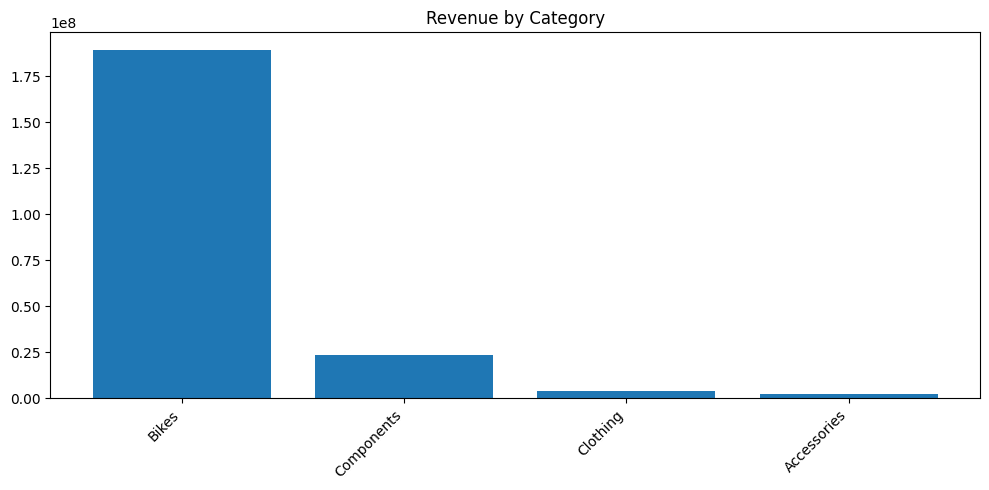

Saved: /content/drive/MyDrive/medallion_advworks/gold/plots/01_revenue_by_category.png


In [ ]:
rev_cat = (fact.join(prod, fact.product_id == prod.ProductID, "left")
    .withColumn("CategoryName", F.coalesce(F.col("CategoryName"), F.lit("Unknown")))
    .groupBy("CategoryName")
    .agg(F.sum("revenue").alias("revenue"))
    .orderBy(F.desc("revenue"))
)

pdf = rev_cat.toPandas()
save_bar(pdf, "CategoryName","revenue","Revenue by Category","01_revenue_by_category.png")

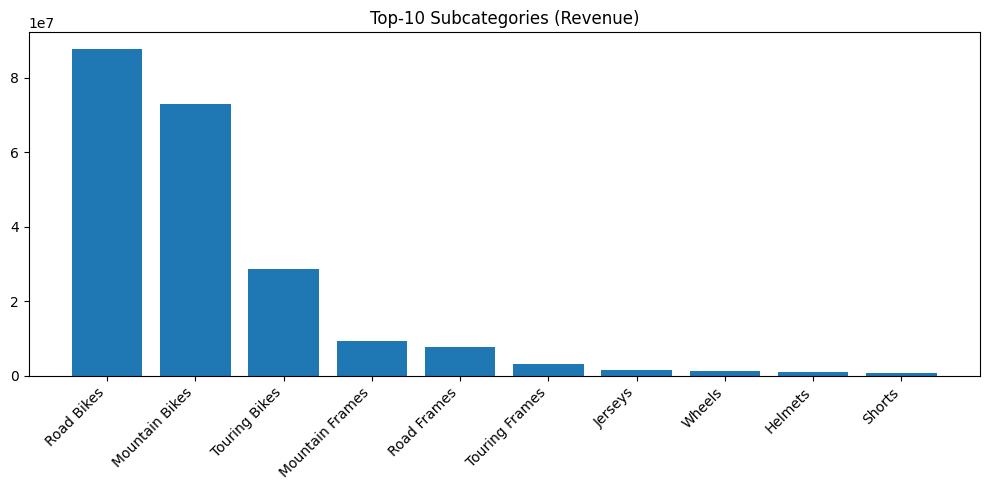

Saved: /content/drive/MyDrive/medallion_advworks/gold/plots/02_top10_subcategories.png


In [ ]:
rev_sub = (fact.join(prod, fact.product_id == prod.ProductID, "left")
    .withColumn("SubcategoryName", F.coalesce(F.col("SubcategoryName"), F.lit("Unknown")))
    .groupBy("SubcategoryName")
    .agg(F.sum("revenue").alias("revenue"))
    .orderBy(F.desc("revenue"))
)

pdf = rev_sub.toPandas().head(10)
save_bar(pdf, "SubcategoryName","revenue","Top-10 Subcategories (Revenue)","02_top10_subcategories.png")

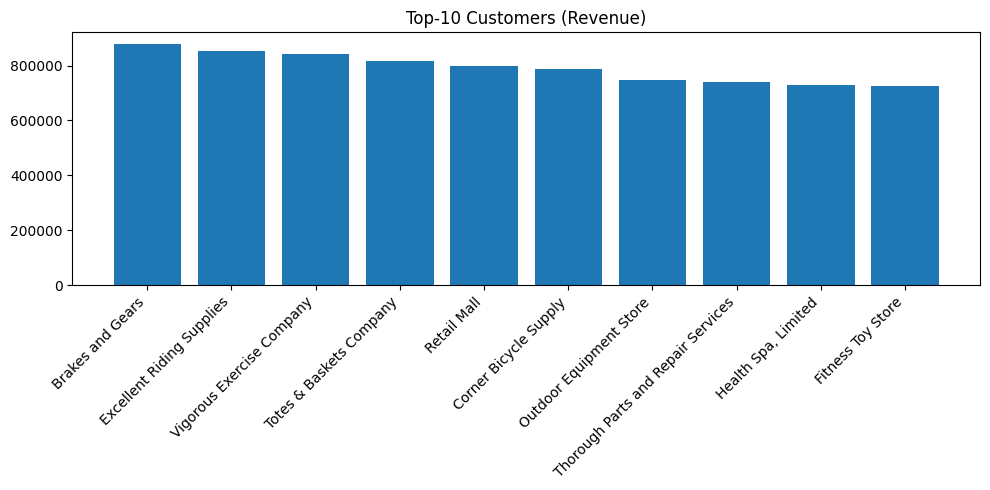

Saved: /content/drive/MyDrive/medallion_advworks/gold/plots/03_top10_customers.png


In [ ]:
rev_cust = (fact.join(cust, fact.customer_id == cust.CustomerID, "left")
    .withColumn("CustomerName", F.coalesce(F.col("CustomerName"), F.lit("Unknown")))
    .groupBy("CustomerName")
    .agg(F.sum("revenue").alias("revenue"))
    .orderBy(F.desc("revenue"))
)

pdf = rev_cust.toPandas().head(10)
save_bar(pdf, "CustomerName","revenue","Top-10 Customers (Revenue)","03_top10_customers.png")

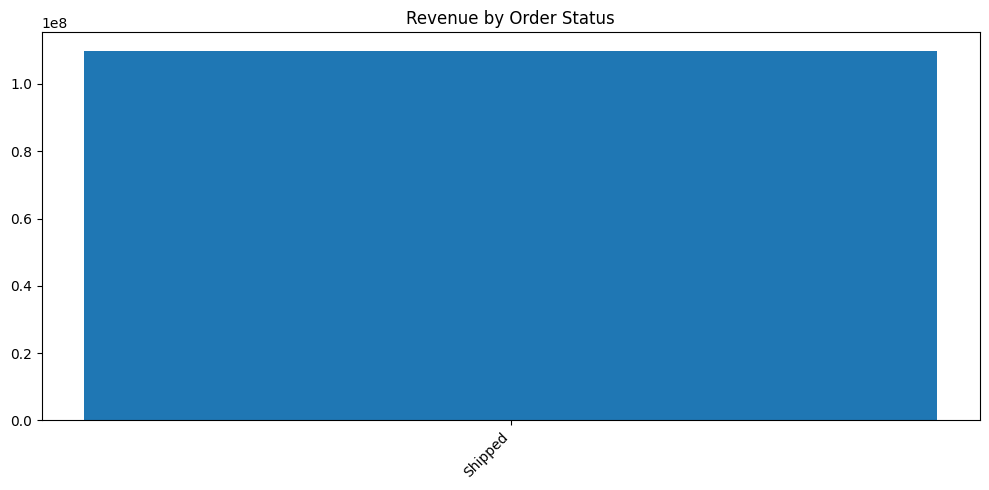

Saved: /content/drive/MyDrive/medallion_advworks/gold/plots/04_revenue_by_status.png


In [ ]:
rev_status = (fact.groupBy("OrderStatus")
    .agg(F.sum("revenue").alias("revenue"))
    .orderBy(F.desc("revenue"))
)

pdf = rev_status.toPandas()
save_bar(pdf, "OrderStatus","revenue","Revenue by Order Status","04_revenue_by_status.png")

In [ ]:
fact_geo = fact.join(geo, fact.bill_address_id == geo.AddressID, "left") \
    .withColumn("CountryName", F.coalesce(F.col("CountryName"), F.lit("Unknown"))) \
    .withColumn("StateName", F.coalesce(F.col("StateName"), F.lit("Unknown"))) \
    .withColumn("City", F.coalesce(F.col("City"), F.lit("Unknown")))

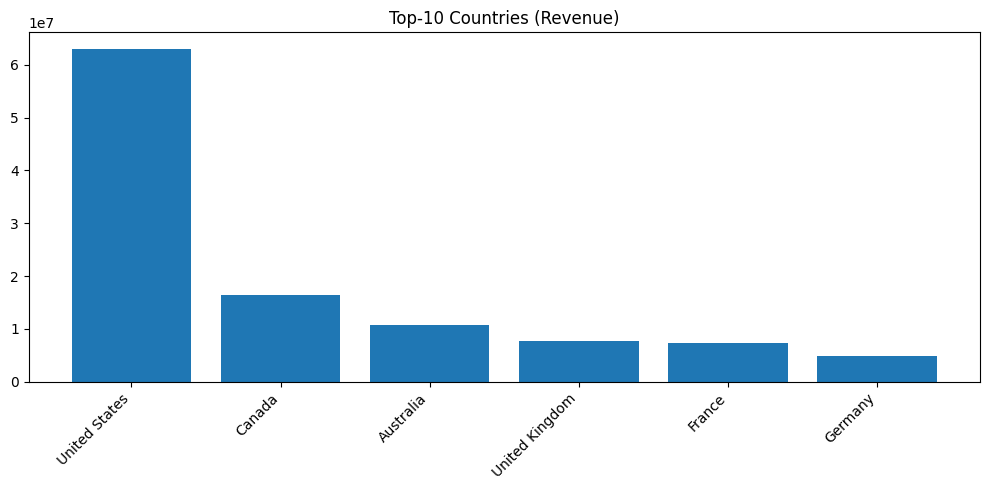

Saved: /content/drive/MyDrive/medallion_advworks/gold/plots/05_top10_countries.png


In [ ]:
rev_country = (fact_geo.groupBy("CountryName")
    .agg(F.sum("revenue").alias("revenue"))
    .orderBy(F.desc("revenue"))
)

pdf = rev_country.toPandas().head(10)
save_bar(pdf, "CountryName","revenue","Top-10 Countries (Revenue)","05_top10_countries.png")

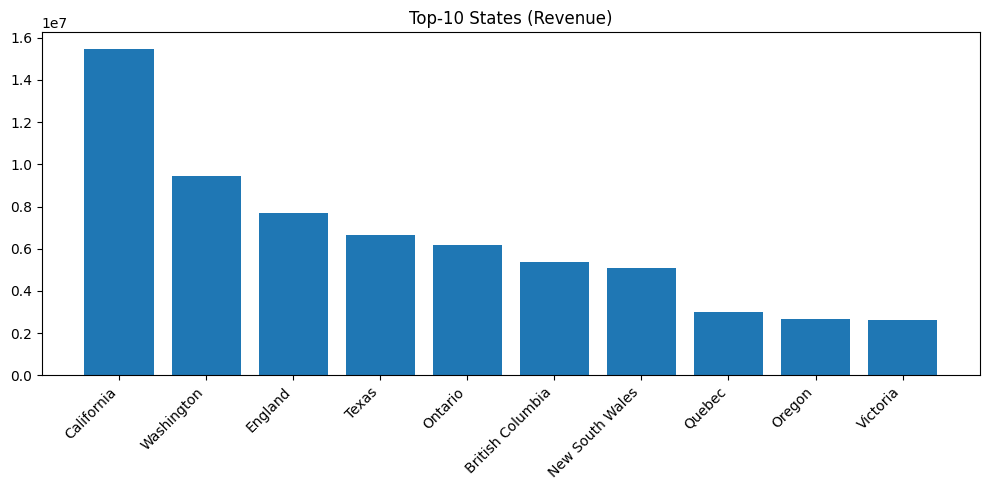

Saved: /content/drive/MyDrive/medallion_advworks/gold/plots/06_top10_states.png


In [ ]:
rev_state = (fact_geo.groupBy("StateName")
    .agg(F.sum("revenue").alias("revenue"))
    .orderBy(F.desc("revenue"))
)

pdf = rev_state.toPandas().head(10)
save_bar(pdf, "StateName","revenue","Top-10 States (Revenue)","06_top10_states.png")

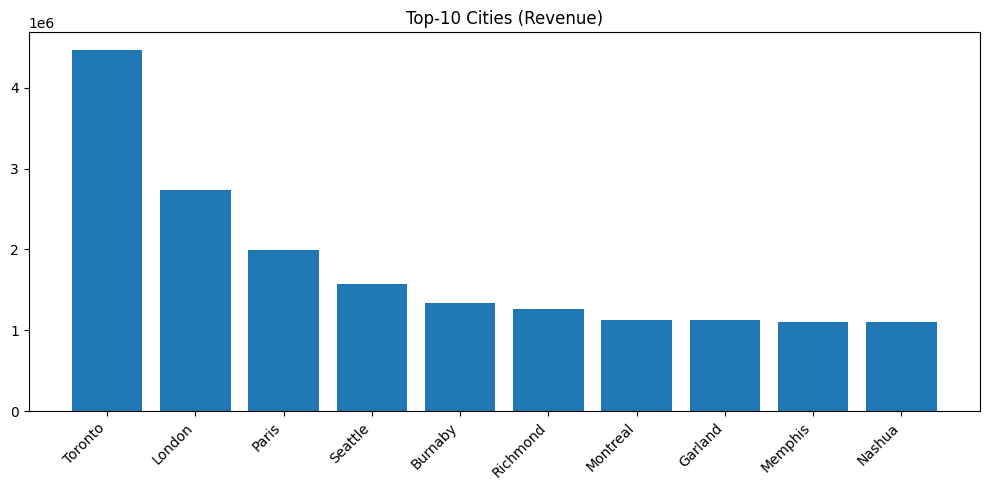

Saved: /content/drive/MyDrive/medallion_advworks/gold/plots/07_top10_cities.png


In [ ]:
rev_city = (fact_geo.groupBy("City")
    .agg(F.sum("revenue").alias("revenue"))
    .orderBy(F.desc("revenue"))
)

pdf = rev_city.toPandas().head(10)
save_bar(pdf, "City","revenue","Top-10 Cities (Revenue)","07_top10_cities.png")

In [ ]:
import os, shutil

def exists(path):
    return os.path.exists(path) and len(os.listdir(path)) > 0

def safe_write_parquet(df, path, repartition_n=1):
    """Drive-safe write: write to temp folder then swap."""
    tmp = path + "__tmp"
    spark.catalog.clearCache()
    # remove temp if exists
    if os.path.exists(tmp):
        shutil.rmtree(tmp, ignore_errors=True)
    (df.repartition(repartition_n)
       .write.mode("overwrite").parquet(tmp))
    spark.catalog.clearCache()
    # swap
    if os.path.exists(path):
        shutil.rmtree(path, ignore_errors=True)
    shutil.move(tmp, path)

def write_gold(df, name):
    path = f"{GOLD}/{name}"
    safe_write_parquet(df, path)
    return path

In [ ]:
orders = spark.read.parquet(silver_orders_path)

min_date = orders.select(F.min("OrderDate")).first()[0]
max_date = orders.select(F.max("OrderDate")).first()[0]

dim_date = (spark.range(1)
    .select(F.explode(F.sequence(F.lit(min_date), F.lit(max_date))).alias("date"))
    .withColumn("date_key", F.date_format("date","yyyyMMdd").cast("int"))
    .withColumn("year", F.year("date"))
    .withColumn("quarter", F.quarter("date"))
    .withColumn("month", F.month("date"))
    .withColumn("month_name", F.date_format("date", "MMMM"))
    .withColumn("day", F.dayofmonth("date"))
    .withColumn("day_of_week", F.date_format("date", "E"))
    .withColumn("week_of_year", F.weekofyear("date"))
)

dim_date_path = write_gold(dim_date, "dim_date")
spark.read.parquet(dim_date_path).show(5)

+----------+--------+----+-------+-----+----------+---+-----------+------------+
|      date|date_key|year|quarter|month|month_name|day|day_of_week|week_of_year|
+----------+--------+----+-------+-----+----------+---+-----------+------------+
|2011-05-31|20110531|2011|      2|    5|       May| 31|        Tue|          22|
|2011-06-01|20110601|2011|      2|    6|      June|  1|        Wed|          22|
|2011-06-02|20110602|2011|      2|    6|      June|  2|        Thu|          22|
|2011-06-03|20110603|2011|      2|    6|      June|  3|        Fri|          22|
|2011-06-04|20110604|2011|      2|    6|      June|  4|        Sat|          22|
+----------+--------+----+-------+-----+----------+---+-----------+------------+
only showing top 5 rows


In [ ]:
dim_order_status = spark.createDataFrame(
    [(1,"In process"),(2,"Approved"),(3,"Backordered"),(4,"Rejected"),(5,"Shipped"),(6,"Cancelled")],
    ["status_code","status_name"]
).withColumn("order_status_key", F.col("status_code").cast("int"))

dim_order_status_path = write_gold(dim_order_status, "dim_order_status")
spark.read.parquet(dim_order_status_path).show()

+-----------+-----------+----------------+
|status_code|status_name|order_status_key|
+-----------+-----------+----------------+
|          1| In process|               1|
|          2|   Approved|               2|
|          3|Backordered|               3|
|          4|   Rejected|               4|
|          5|    Shipped|               5|
|          6|  Cancelled|               6|
+-----------+-----------+----------------+



In [ ]:
geo = spark.read.parquet(silver_geo_path)

dim_geography = (geo
    .select(
        F.col("AddressID").cast("int").alias("address_id"),
        "AddressLine1","AddressLine2","City","PostalCode",
        "StateProvinceCode", F.col("StateName").alias("state"),
        "CountryRegionCode", F.col("CountryName").alias("country"),
        F.col("TerritoryID").cast("int").alias("territory_id")
    )
    .withColumn("geography_key", F.col("address_id"))
)

dim_geography_path = write_gold(dim_geography, "dim_geography")
spark.read.parquet(dim_geography_path).show(5, truncate=False)

+----------+--------------------+------------+-------+----------+-----------------+----------+-----------------+-------------+------------+-------------+
|address_id|AddressLine1        |AddressLine2|City   |PostalCode|StateProvinceCode|state     |CountryRegionCode|country      |territory_id|geography_key|
+----------+--------------------+------------+-------+----------+-----------------+----------+-----------------+-------------+------------+-------------+
|1         |1970 Napa Ct.       |NULL        |Bothell|98011     |WA               |Washington|US               |United States|1           |1            |
|2         |9833 Mt. Dias Blv.  |NULL        |Bothell|98011     |WA               |Washington|US               |United States|1           |2            |
|3         |7484 Roundtree Drive|NULL        |Bothell|98011     |WA               |Washington|US               |United States|1           |3            |
|4         |9539 Glenside Dr    |NULL        |Bothell|98011     |WA         

## 6. Implementatie van SCD Type 2

Hier implementeer ik Slowly Changing Dimension Type 2.

Waarom?
Sommige dimensies (zoals Customer of Product) kunnen wijzigen doorheen de tijd.

In plaats van oude data te overschrijven:
- Sluit ik oude records af met een end_date
- Maak ik een nieuwe record aan
- Gebruik ik current_flag om actieve records te markeren

Zo kunnen we historische analyses correct uitvoeren.

In [ ]:
from pyspark.sql.window import Window
import os, shutil

def scd2_upsert(source_df, target_path, business_key, tracked_cols):
    """Snapshot-based SCD Type 2 (Drive-safe write via temp swap)."""

    src = (source_df
        .withColumn(
            "attr_hash",
            F.sha2(
                F.concat_ws("||", *[F.coalesce(F.col(c).cast("string"), F.lit("")) for c in tracked_cols]),
                256
            )
        )
    )

    today = F.current_date()

    def safe_swap_write(df, path):
        tmp = path + "__tmp"
        spark.catalog.clearCache()
        if os.path.exists(tmp):
            shutil.rmtree(tmp, ignore_errors=True)
        df.repartition(1).write.mode("overwrite").parquet(tmp)
        spark.catalog.clearCache()
        if os.path.exists(path):
            shutil.rmtree(path, ignore_errors=True)
        shutil.move(tmp, path)

    if not exists(target_path):
        w = Window.orderBy(F.col(business_key))
        init = (src
            .withColumn("surrogate_key", F.row_number().over(w))
            .withColumn("start_date", today)
            .withColumn("end_date", F.lit("9999-12-31").cast("date"))
            .withColumn("current_flag", F.lit("Y"))
            .drop("attr_hash")
        )
        safe_swap_write(init, target_path)
        return

    tgt = spark.read.parquet(target_path)

    tgt_current = (tgt
        .filter(F.col("current_flag") == "Y")
        .withColumn(
            "attr_hash",
            F.sha2(
                F.concat_ws("||", *[F.coalesce(F.col(c).cast("string"), F.lit("")) for c in tracked_cols]),
                256
            )
        )
    )

    changes = (src.alias("s")
        .join(tgt_current.alias("t"), on=[F.col(f"s.{business_key}") == F.col(f"t.{business_key}")], how="left")
        .where(F.col("t."+business_key).isNull() | (F.col("s.attr_hash") != F.col("t.attr_hash")))
        .select("s.*")
    )

    expired = (tgt.alias("t")
        .join(changes.select(business_key).distinct().alias("c"), on=business_key, how="left")
        .withColumn(
            "end_date",
            F.when((F.col("t.current_flag")=="Y") & F.col("c."+business_key).isNotNull(),
                   F.date_sub(today, 1)).otherwise(F.col("t.end_date"))
        )
        .withColumn(
            "current_flag",
            F.when((F.col("t.current_flag")=="Y") & F.col("c."+business_key).isNotNull(),
                   F.lit("N")).otherwise(F.col("t.current_flag"))
        )
    )

    max_sk = tgt.agg(F.max("surrogate_key")).first()[0]
    max_sk = 0 if max_sk is None else int(max_sk)

    w = Window.orderBy(F.col(business_key))
    inserts = (changes
        .withColumn("surrogate_key", F.row_number().over(w) + F.lit(max_sk))
        .withColumn("start_date", today)
        .withColumn("end_date", F.lit("9999-12-31").cast("date"))
        .withColumn("current_flag", F.lit("Y"))
    )

    final_dim = (expired.unionByName(inserts, allowMissingColumns=True)
                 .drop("attr_hash"))
    safe_swap_write(final_dim, target_path)

## 7. Dimensie – Customer

Hier bouw ik de klantdimensie.

Belangrijk:
- Ik genereer een surrogate key
- Ik implementeer SCD Type 2
- Ik bewaar historische wijzigingen

Deze dimensie wordt later gebruikt in de fact tabel via de surrogate key.

In [ ]:
customers = spark.read.parquet(silver_customers_path)

dim_customer_src = (customers
    .select(
        F.col("CustomerID").cast("int").alias("customer_id"),
        F.col("CustomerName").alias("customer_name"),
        F.col("PersonType").alias("person_type"),
        F.col("TerritoryID").cast("int").alias("territory_id"),
        F.col("AccountNumber").alias("account_number")
    )
)

dim_customer_path = f"{GOLD}/dim_customer"
scd2_upsert(dim_customer_src, dim_customer_path,
            business_key="customer_id",
            tracked_cols=["customer_name","person_type","territory_id","account_number"])

spark.read.parquet(dim_customer_path).orderBy(F.desc("current_flag"), "customer_id").show(20, truncate=False)

+-----------+--------------------------+-----------+------------+--------------+-------------+----------+----------+------------+
|customer_id|customer_name             |person_type|territory_id|account_number|surrogate_key|start_date|end_date  |current_flag|
+-----------+--------------------------+-----------+------------+--------------+-------------+----------+----------+------------+
|1          |A Bike Store              |NULL       |1           |AW00000001    |1            |2026-02-24|9999-12-31|Y           |
|2          |Progressive Sports        |NULL       |1           |AW00000002    |2            |2026-02-24|9999-12-31|Y           |
|3          |Advanced Bike Components  |NULL       |4           |AW00000003    |3            |2026-02-24|9999-12-31|Y           |
|4          |Modular Cycle Systems     |NULL       |4           |AW00000004    |4            |2026-02-24|9999-12-31|Y           |
|5          |Metropolitan Sports Supply|NULL       |4           |AW00000005    |5         

## 8. Dimensie – Product

Hier maak ik de productdimensie aan.

Deze bevat:
- Product informatie
- Categorie
- Subcategorie

Ook hier gebruik ik SCD Type 2 om wijzigingen historisch bij te houden.

In [ ]:
import shutil, os, glob

def nuke_path(path):
    spark.catalog.clearCache()
    try:
        spark._jsc.sc().getPersistentRDDs().clear()
    except:
        pass

    if os.path.exists(path):
        shutil.rmtree(path, ignore_errors=True)

dim_product_path = f"{GOLD}/dim_product"
nuke_path(dim_product_path)

print("dim_product folder cleared:", dim_product_path, "exists?", os.path.exists(dim_product_path))

dim_product folder cleared: /content/drive/MyDrive/medallion_advworks/gold/dim_product exists? False


In [ ]:
products = spark.read.parquet(silver_products_path)

def safe_euro_double(col):
    s = F.trim(F.col(col).cast("string"))
    s = F.regexp_replace(s, ",", ".")
    s = F.regexp_replace(s, r"[^0-9\.\-]", "")
    return F.when(s.rlike(r"^-?\d+(\.\d+)?$"), s.cast("double")).otherwise(F.lit(None).cast("double"))

dim_product_src = (products
    .select(
        F.col("ProductID").cast("int").alias("product_id"),
        F.col("Name").alias("product_name"),
        F.col("ProductNumber").alias("product_number"),
        F.col("Color").alias("color"),
        F.col("Size").alias("size"),
        F.col("SubcategoryName").alias("subcategory"),
        F.col("CategoryName").alias("category"),
        safe_euro_double("ListPrice").alias("list_price"),
    )
)

dim_product_path = f"{GOLD}/dim_product"
scd2_upsert(
    dim_product_src,
    dim_product_path,
    business_key="product_id",
    tracked_cols=["product_name","product_number","color","size","subcategory","category","list_price"]
)

spark.read.parquet(dim_product_path).orderBy(F.desc("current_flag"), "product_id").show(20, truncate=False)

+----------+---------------------+--------------+------+----+-----------+--------+----------+-------------+----------+----------+------------+
|product_id|product_name         |product_number|color |size|subcategory|category|list_price|surrogate_key|start_date|end_date  |current_flag|
+----------+---------------------+--------------+------+----+-----------+--------+----------+-------------+----------+----------+------------+
|NULL      |Name                 |ProductNumber |Color |Size|NULL       |NULL    |NULL      |1            |2026-02-24|9999-12-31|Y           |
|1         |Adjustable Race      |AR-5381       |NULL  |NULL|NULL       |NULL    |0.0       |2            |2026-02-24|9999-12-31|Y           |
|1         |Adjustable Race      |AR-5381       |NULL  |NULL|NULL       |NULL    |0.0       |3            |2026-02-24|9999-12-31|Y           |
|2         |Bearing Ball         |BA-8327       |NULL  |NULL|NULL       |NULL    |0.0       |4            |2026-02-24|9999-12-31|Y           |

## 11. Fact Table – Revenue

Hier bouw ik de centrale fact tabel.

Deze bevat:
- Surrogate keys naar alle dimensies
- Measures zoals revenue en quantity

Revenue wordt berekend als:
Quantity × UnitPrice × (1 - Discount)

Deze fact tabel vormt de kern van het stermodel
en beantwoordt de businessvraag rond omzet.

In [ ]:
fact = spark.read.parquet(f"{GOLD}/fact_revenue")

dim_cust_cur = spark.read.parquet(dim_customer_path).filter("current_flag='Y'") \
    .select("customer_id","surrogate_key").withColumnRenamed("surrogate_key","customer_key")

dim_prod_cur = spark.read.parquet(dim_product_path).filter("current_flag='Y'") \
    .select("product_id","surrogate_key").withColumnRenamed("surrogate_key","product_key")

dim_geo = spark.read.parquet(dim_geography_path).select("address_id","geography_key")
dim_status = spark.read.parquet(dim_order_status_path).select("status_code","order_status_key")

fact_gold = (fact
    .join(dim_cust_cur, on="customer_id", how="left")
    .join(dim_prod_cur, on="product_id", how="left")
    .join(dim_geo, fact.bill_address_id == dim_geo.address_id, "left")
    .withColumnRenamed("geography_key","bill_geography_key")
    .drop(dim_geo.address_id)
    .join(dim_status, on="status_code", how="left")
    .select(
        "sales_order_id","sales_order_detail_id",
        "order_date_key",
        "order_status_key",
        "customer_key",
        "product_key",
        "bill_geography_key",
        "order_qty","unit_price","unit_price_discount","revenue"
    )
)

fact_gold_path = write_gold(fact_gold, "fact_sales")
spark.read.parquet(fact_gold_path).show(5, truncate=False)
fact_sales = spark.read.parquet(fact_gold_path)

fact_sales.select(
    F.count("*").alias("rows"),
    F.sum(F.col("customer_key").isNull().cast("int")).alias("customer_key_nulls"),
    F.sum(F.col("product_key").isNull().cast("int")).alias("product_key_nulls"),
    F.sum(F.col("bill_geography_key").isNull().cast("int")).alias("geo_key_nulls"),
    F.sum(F.col("order_status_key").isNull().cast("int")).alias("status_key_nulls"),
    F.sum(F.col("order_date_key").isNull().cast("int")).alias("date_key_nulls"),
).show()

+--------------+---------------------+--------------+----------------+------------+-----------+------------------+---------+----------+-------------------+--------+
|sales_order_id|sales_order_detail_id|order_date_key|order_status_key|customer_key|product_key|bill_geography_key|order_qty|unit_price|unit_price_discount|revenue |
+--------------+---------------------+--------------+----------------+------------+-----------+------------------+---------+----------+-------------------+--------+
|43659         |1                    |20110531      |5               |19527       |563        |985               |1        |2024.994  |0.0                |2024.994|
|43659         |1                    |20110531      |5               |19527       |562        |985               |1        |2024.994  |0.0                |2024.994|
|43659         |2                    |20110531      |5               |19527       |565        |985               |3        |2024.994  |0.0                |6074.982|
|43659    

## Alle files en data worden verwerkt via Google Colab en automatisch opgeslagen in de gekoppelde Google Drive.